# ATiG 2026: LD score regression — answers
29 October 2026 · About 60 minutes · Work in pairs

We use LD score regression (LDSC) to estimate heritability and genetic correlations from
published GWAS results. Run the cells in order and discuss the questions.
[Open in Colab](https://colab.research.google.com/github/bvilhjal/ATIG_2026/blob/main/teaching_days/2026-10-29/LDSC/LDSC_practical_answers.ipynb) and choose File → Save a copy in Drive.

## Setup
Run the three cells. The last one downloads the three GWAS from the
[GWAS Catalog](https://www.ebi.ac.uk/gwas/) (about 260 MB, a few minutes).

In [ ]:
%pip install -q "allelign>=0.2.0" "pldsc @ git+https://github.com/bvilhjal/PLDSC@v0.1.1"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import allelign
from pldsc import load_ld_reference, ldsc_h2_sumstats, ldsc_rg_sumstats

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
#@title Download the GWAS files from the GWAS Catalog (no editing needed)
STUDIES = {'BMI': 'GCST006900', 'TG': 'GCST002216', 'DBP': 'GCST006630'}

paths = {}
for trait, study in STUDIES.items():  # A few minutes the first time.
    paths[trait] = allelign.fetch_ref(study)
    print(trait, study, paths[trait].name)

BMI GCST006900 Meta-analysis_Locke_et_al+UKBiobank_2018_UPDATED.txt.gz
TG GCST002216 24097068-GCST002216-EFO_0004530.h.tsv.gz
DBP GCST006630 Evangelou_30224653_DBP.txt.gz


## Q1. Look at the files

The GWAS are of BMI ([Yengo et al. 2018](https://pubmed.ncbi.nlm.nih.gov/30124842/)),
triglycerides, TG ([Willer et al. 2013](https://pubmed.ncbi.nlm.nih.gov/24097068/)), and diastolic
blood pressure, DBP ([Evangelou et al. 2018](https://pubmed.ncbi.nlm.nih.gov/30224653/)). The BMI and
DBP files are as the authors submitted them. The GWAS Catalog has harmonised the TG file,
adding columns that start with `hm_`.

Find the effect allele, the effect size and its standard error in each file. How do the
files differ?

In [3]:
for trait, path in paths.items():
    print(f'The first rows of the {trait} file:')
    display(pd.read_csv(path, sep=r'\s+', nrows=3, dtype=str))

The first rows of the BMI file:


,CHR,POS,SNP,Tested_Allele,Other_Allele,Freq_Tested_Allele_in_HRS,BETA,SE,P,N
0,7,92383888,rs10,A,C,0.06431,0.0013,0.0042,7.5e-01,598895
1,12,126890980,rs1000000,A,G,0.2219,0.0001,0.0021,9.6e-01,689928
2,4,21618674,rs10000010,T,C,0.5086,-0.0001,0.0016,9.4e-01,785319


The first rows of the TG file:


,hm_variant_id,hm_rsid,hm_chrom,hm_pos,hm_other_allele,hm_effect_allele,hm_beta,hm_odds_ratio,hm_ci_lower,hm_ci_upper,...,standard_error,n,p_value,eaf_ref,chromosome,base_pair_location,ci_lower,odds_ratio,effect_allele_frequency,ci_upper
0,10_9918166_A_G,rs4747841,10,9918166,A,G,-0.002,NaN,NaN,NaN,...,0.0047,90263.00,0.7567,0.4908,10,9918166,NaN,NaN,NaN,NaN
1,10_9918296_C_T,rs4749917,10,9918296,C,T,-0.002,NaN,NaN,NaN,...,0.0047,90263.00,0.7612,0.4908,10,9918296,NaN,NaN,NaN,NaN
2,10_98252982_A_G,rs737656,10,98252982,A,G,-0.0094,NaN,NaN,NaN,...,0.0048,91013.00,0.06856,0.3206,10,98252982,NaN,NaN,NaN,NaN


The first rows of the DBP file:


,MarkerName,Allele1,Allele2,Freq1,Effect,StdErr,P,TotalSampleSize,N_effective
0,10:100000625:SNP,a,g,0.5663,-0.0432,0.0174,0.01294,757601,756275
1,10:100000645:SNP,a,c,0.7935,0.0263,0.0214,0.218,757599,754442
2,10:100001867:SNP,t,c,0.0139,-0.0424,0.0839,0.6128,742538,595603


**Answer.** The effect allele is `Tested_Allele` (BMI), `hm_effect_allele` (TG) and `Allele1`
(DBP); the effect and its SE are `BETA` and `SE`, `hm_beta` and `standard_error`, and `Effect`
and `StdErr`. The TG file keeps the submitted columns next to the harmonised ones, sometimes
with the alleles swapped: for rs4747841 the submitted effect allele is a (beta 0.002) and the
harmonised one G (`hm_beta` −0.002). DBP has no rsIDs, lower-case alleles and effects in mmHg.

## Q2. Read the files

allelign reads all three formats (Table 1) and takes DBP's positions from `MarkerName`.
The harmonised TG file has positions on genome build GRCh38, but our LD reference uses
GRCh37, so we match TG by rsID instead.

Which columns were not found in each file?

In [4]:
columns = {}
for trait, path in paths.items():
    columns[trait] = allelign.inspect_columns(path)['mapping']

print('Table 1. File columns used by allelign; blank if not found.')
display(pd.DataFrame(columns).fillna(''))

Table 1. File columns used by allelign; blank if not found.


,BMI,TG,DBP
id,SNP,hm_rsid,MarkerName
chrom,CHR,hm_chrom,
pos,POS,hm_pos,
ea,Tested_Allele,hm_effect_allele,Allele1
oa,Other_Allele,hm_other_allele,Allele2
beta,BETA,hm_beta,Effect
se,SE,standard_error,StdErr
pval,P,p_value,P
n_eff,N,n,N_effective
or,,odds_ratio,


In [5]:
def read_gwas(path):
    """Read a GWAS file. Harmonised GWAS Catalog files (*.h.tsv.gz) have GRCh38
    positions, and our LD reference is GRCh37, so for those we match by rsID only."""
    sumstats = allelign.read_sumstats(path)
    if path.name.endswith('.h.tsv.gz'):
        sumstats.chrom[:] = ''
        sumstats.pos[:] = 0
    return sumstats


gwas = {}
for trait, path in paths.items():  # About 30 seconds.
    gwas[trait] = read_gwas(path)
    print(f'{trait}: {len(gwas[trait]):,} variants')

BMI: 2,336,269 variants


TG: 2,432,313 variants


DBP: 7,160,657 variants


**Answer.** allelign found no allele frequency for BMI (its HRS frequency column is not
recognised) and no position columns for DBP, whose positions it takes from `MarkerName`. The TG
file has everything, but its positions are on GRCh38, so TG is matched by rsID.

## Q3. Match to the LD reference

PLDSC comes with LD scores for about 1.2 million HapMap3 SNPs, from Europeans in the 1000
Genomes Project. We keep only these SNPs and flip each GWAS to the same allele, `a1`
(Table 2). Table 3 shows the result for BMI.

Why must all traits use the same allele? Allele C of rs1421085 in *FTO* raises BMI: does
it raise TG and DBP? Which trait has the most associated regions in Figure 1?

In [6]:
ref = load_ld_reference('hm3-eur')

aligned = {}
counts = {}
for trait, sumstats in gwas.items():
    keep, qc = allelign.qc_sumstats(sumstats)
    aligned[trait] = allelign.harmonize(sumstats.subset(keep), ref.variants)
    counts[trait] = {'in file': len(sumstats),
                     'matched': aligned[trait].log['n_matched'],
                     'flipped': aligned[trait].log['n_flipped']}

print('Table 2. Variants in each file, matched to the reference, and flipped to a1.')
display(pd.DataFrame(counts))

Table 2. Variants in each file, matched to the reference, and flipped to a1.


,BMI,TG,DBP
in file,2336269,2432313,7160657
matched,986154,988987,1133898
flipped,461674,296605,531032


In [7]:
snps = {}
for trait, h in aligned.items():
    rows = h.var_index  # Rows of the LD reference.
    z = h.beta / h.se
    snps[trait] = pd.DataFrame({'snp': ref.variants.id[rows],
                                'chrom': ref.variants.chrom[rows].astype(int),
                                'pos': ref.variants.pos[rows],
                                'a1': ref.variants.a1[rows],
                                'z': z,
                                'chi2': z**2,
                                'p': 2 * stats.norm.sf(np.abs(z)),
                                'n': h.n_eff.astype(int),
                                'ld_score': ref.scores[rows]})

print('Table 3. The first aligned SNPs for BMI (z is for allele a1).')
display(snps['BMI'].head())

Table 3. The first aligned SNPs for BMI (z is for allele a1).


,snp,chrom,pos,a1,z,chi2,p,n,ld_score
0,rs4040617,1,779322,G,-0.778,0.605,0.437,587624,85.659
1,rs2980300,1,785989,T,-0.704,0.495,0.482,585492,89.525
2,rs4075116,1,1003629,C,-1.950,3.802,0.051,680426,80.322
3,rs3934834,1,1005806,T,1.640,2.690,0.101,635407,53.097
4,rs3766192,1,1017197,C,-0.389,0.151,0.697,669144,92.250


In [8]:
snp = 'rs1421085'  # TRY: rs1260326 (GCKR) or rs13107325 (SLC39A8)
for trait, table in snps.items():
    row = table[table['snp'] == snp]
    print(f"{trait}: z = {row['z'].item():.2f} for allele {row['a1'].item()}")

BMI: z = 45.76 for allele C
TG: z = 5.06 for allele C
DBP: z = -3.65 for allele C


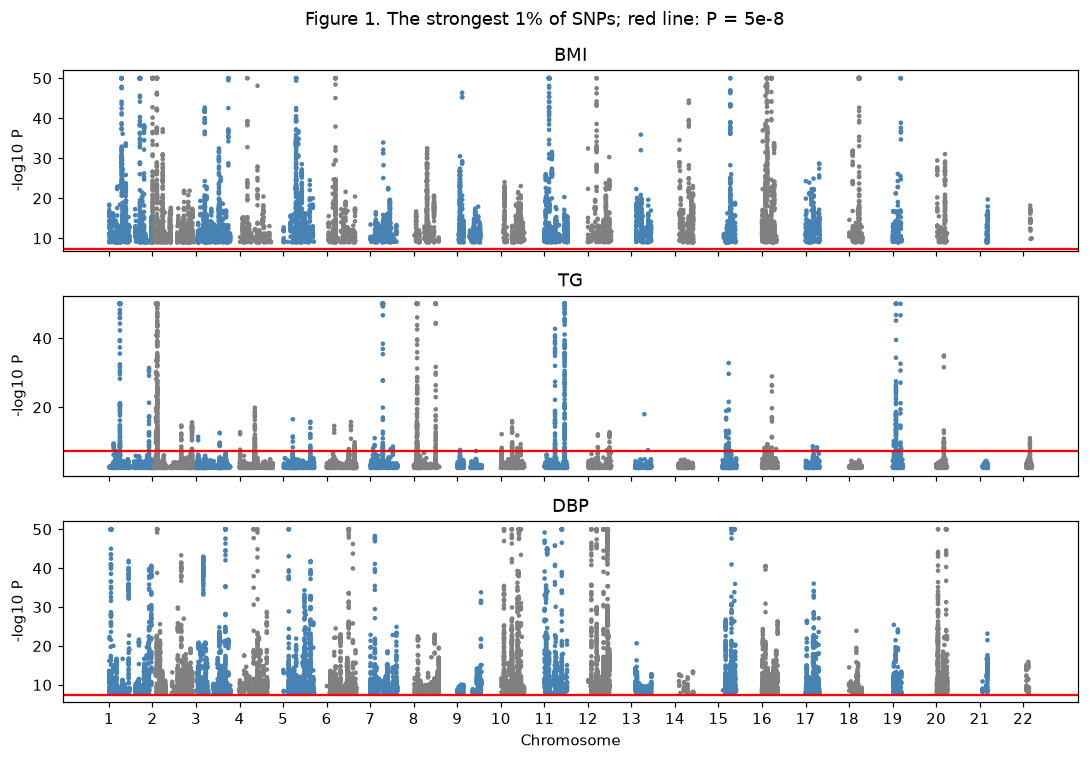

In [9]:
def manhattan(ax, table):
    """Plot the 1% of SNPs with the smallest P values along the genome."""
    top = table.nsmallest(len(table) // 100, 'p')
    x = top['chrom'] + top['pos'] / 250e6        # Chromosomes side by side.
    y = -np.log10(top['p'].clip(lower=1e-50))     # P below 1e-50 is drawn at 50.
    colour = np.where(top['chrom'] % 2 == 0, 'grey', 'steelblue')
    ax.scatter(x, y, c=colour, s=4)
    ax.axhline(-np.log10(5e-8), color='red')      # Genome-wide significance.
    ax.set_xticks(range(1, 23))
    ax.set_ylabel('-log10 P')


fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, trait in zip(axes, snps):
    manhattan(ax, snps[trait])
    ax.set_title(trait)
axes[-1].set_xlabel('Chromosome')
fig.suptitle('Figure 1. The strongest 1% of SNPs; red line: P = 5e-8')
plt.tight_layout()
plt.show()

**Answer.** Bivariate LDSC multiplies the z scores of two traits, so a SNP reported for
opposite alleles would add to the sum with the wrong sign. Between 30% and 47% of the SNPs
in each file were flipped. Allele C of rs1421085 raises BMI (z = 45.76) and TG (z = 5.06) but lowers
BMI-adjusted DBP (z = −3.65); see Q5. In Figure 1, BMI and DBP have genome-wide significant
SNPs on every chromosome, while TG has a few strong regions.

## Q4. Heritability

LDSC regresses each SNP's χ² on its LD score $\ell_j$:

$$E[\chi^2_j] = 1 + Na + \frac{N h^2}{M}\,\ell_j,$$

where $N$ is the sample size and $M$ the number of SNPs. The slope gives the heritability
$h^2$, and the intercept $1 + Na$ measures confounding (Table 4, Figure 2).

Which trait is most heritable? Is there much confounding? Set `M = ref.m_snps` and rerun:
what changes?

In [10]:
M = ref.m_snps_5_50  # SNPs with allele frequency 5-50%. TRY: ref.m_snps

fits = {}
h2_table = {}
for trait, sumstats in gwas.items():  # About 30 seconds.
    fit = ldsc_h2_sumstats(sumstats, ref.variants, ref.scores, m_snps=M).estimate
    fits[trait] = fit
    h2_table[trait] = {'h2': fit.h2, 'SE': fit.h2_se, 'intercept': fit.intercept,
                       'lambda GC': allelign.genomic_inflation(z=snps[trait]['z'].to_numpy())}

print(f'Table 4. SNP heritability with M = {M:,}.')
display(pd.DataFrame(h2_table).T)

Table 4. SNP heritability with M = 5,961,159.


,h2,SE,intercept,lambda GC
BMI,0.214,0.008,1.159,2.714
TG,0.178,0.022,0.960,1.134
DBP,0.137,0.007,1.211,2.012


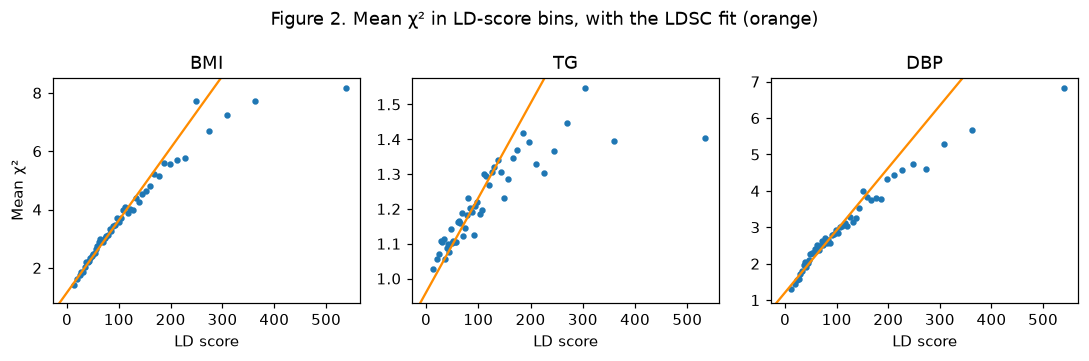

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, trait in zip(axes, snps):
    table = snps[trait]
    table = table[table['chi2'] <= np.maximum(80, table['n'] / 1000)]  # The SNPs LDSC uses.
    bins = pd.qcut(table['ld_score'], 50)                              # 50 bins of equal size.
    means = table.groupby(bins, observed=True)[['ld_score', 'chi2']].mean()
    ax.scatter(means['ld_score'], means['chi2'], s=10)

    fit = fits[trait]
    slope = table['n'].median() * fit.h2 / M
    ax.axline((0, fit.intercept), slope=slope, color='darkorange')   # The LDSC fit.
    ax.set_title(trait)
    ax.set_xlabel('LD score')
axes[0].set_ylabel('Mean χ²')
fig.suptitle('Figure 2. Mean χ² in LD-score bins, with the LDSC fit (orange)')
plt.tight_layout()
plt.show()

**Answer.** BMI 0.214 (SE 0.008), TG 0.178 (SE 0.022) and DBP 0.137 (SE 0.007). λGC is up to
2.7, but the intercepts are close to one (BMI 1.159, DBP 1.211), so most of the inflation is
polygenic signal. TG's intercept, 0.960, is below one because the TG studies were corrected
for genomic control. With `M = ref.m_snps`, every $h^2$ is 1.68 times larger: M decides which
SNPs $h^2$ refers to.

## Q5. Genetic correlations

Bivariate LDSC regresses the product of two traits' z scores on LD score. The slope, scaled
by the two heritabilities, gives the genetic correlation $r_g$, and the intercept reflects
people who are in both GWAS (Table 5, Figure 3).

Which traits are genetically correlated? UK Biobank is in both the BMI and the DBP GWAS, and
DBP was adjusted for BMI. Can you explain the BMI–DBP result?

Table 5. Genetic correlations.


,rg,SE,intercept
BMI–TG,0.283,0.030,0.051
BMI–DBP,-0.059,0.017,0.003
TG–DBP,0.095,0.027,0.036


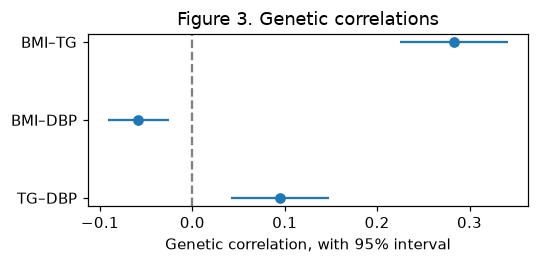

In [12]:
rg_table = {}
for trait1, trait2 in [('BMI', 'TG'), ('BMI', 'DBP'), ('TG', 'DBP')]:  # About a minute.
    fit = ldsc_rg_sumstats(gwas[trait1], gwas[trait2], ref.variants, ref.scores,
                           m_snps=M, ncores=2).estimate
    rg_table[f'{trait1}–{trait2}'] = {'rg': fit.rg, 'SE': fit.rg_se, 'intercept': fit.gcov_intercept}

results = pd.DataFrame(rg_table).T
print('Table 5. Genetic correlations.')
display(results)

plt.figure(figsize=(5, 2.5))
plt.errorbar(results['rg'], results.index, xerr=1.96 * results['SE'], fmt='o')
plt.gca().invert_yaxis()  # Same order as Table 5.
plt.axvline(0, color='grey', linestyle='--')
plt.xlabel('Genetic correlation, with 95% interval')
plt.title('Figure 3. Genetic correlations')
plt.tight_layout()
plt.show()

**Answer.** BMI–TG gives $r_g$ = 0.283 (SE 0.030) and TG–DBP 0.095 (SE 0.027). BMI–DBP is
negative, −0.059 (SE 0.017), although higher BMI goes with higher blood pressure. Adjusting
DBP for BMI subtracts part of each SNP's BMI effect, which pushes the genetic correlation
with BMI down. This is collider bias
([Aschard et al. 2015](https://pubmed.ncbi.nlm.nih.gov/25640676/)). The BMI–TG intercept,
0.051, reflects people in both GWAS; the BMI–DBP intercept is close to zero because
BMI-adjusted DBP is uncorrelated with BMI.

## Q6. Conclude

Write three sentences: the BMI–TG $r_g$ with its standard error, why it does not show that
BMI raises TG, and what the BMI–DBP result teaches you about published GWAS.

**Answer.** BMI and TG have a genetic correlation of 0.28 (SE 0.03). It could come from BMI
affecting TG, the reverse, pleiotropy or a shared cause, and MR or other designs are needed
to tell these apart. Before using a published GWAS, check what it was adjusted for.

## Going further (optional)

- Try other traits. Find a study with full summary statistics in the
  [GWAS Catalog](https://www.ebi.ac.uk/gwas/downloads/summary-statistics) and put its accession
  in the cell below. European-ancestry GWAS fit our LD reference best.
- Ask an AI model to write LDSC from scratch in NumPy, using the columns `chi2`, `n` and
  `ld_score` of `snps['BMI']`, and compare with Table 4.

In [ ]:
study = 'GCST002223'  # HDL. TRY: GCST002222 (LDL), GCST006901 (height) or another study

new = read_gwas(allelign.fetch_ref(study))
print(study, ldsc_h2_sumstats(new, ref.variants, ref.scores, m_snps=M).estimate)
for trait in ['BMI', 'TG', 'DBP']:
    fit = ldsc_rg_sumstats(gwas[trait], new, ref.variants, ref.scores,
                           m_snps=M, ncores=2).estimate
    print(f'{trait}–{study}: rg {fit.rg:.3f} (SE {fit.rg_se:.3f})')

## Data and methods

All three GWAS are European-ancestry meta-analyses from the GWAS Catalog
([GCST006900](https://www.ebi.ac.uk/gwas/studies/GCST006900),
[GCST002216](https://www.ebi.ac.uk/gwas/studies/GCST002216),
[GCST006630](https://www.ebi.ac.uk/gwas/studies/GCST006630); see
[`data/sources.json`](data/sources.json)), downloaded with allelign. The LD scores are the 1000 Genomes European scores
released with LDSC ([Zenodo 7768714](https://doi.org/10.5281/zenodo.7768714)); PLDSC leaves
out about 30,000 SNPs in long-range LD regions such as the MHC, and SNPs with χ² above
max(80, N/1000). Background: [Bulik-Sullivan et al. 2015a](https://pubmed.ncbi.nlm.nih.gov/25642630/)
and [2015b](https://pubmed.ncbi.nlm.nih.gov/26414676/).